# 第091讲 CPU可复现实验
先读lecture.md与lab.md。本笔记本实际运行相同脚本、测试并显示图像；输出不是手工粘贴。

In [1]:
import sys, pathlib, subprocess, json
print(sys.version)
print('Working directory:', pathlib.Path.cwd())

3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]
Working directory: /workspace/scratch/1577d0a62398/tutorials-20261019/machine-learning/units/091


In [2]:
result=subprocess.run([sys.executable,'experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout)
print('Script exit:',result.returncode)

{
  "seed": 91,
  "device": "cpu",
  "torch": "2.14.1+cpu",
  "python": "3.12.14",
  "hand_output": [
    [
      -4.0,
      -4.0
    ],
    [
      -4.0,
      -4.0
    ]
  ],
  "audits": [
    {
      "stride": 1,
      "padding": 0,
      "shape": [
        2,
        3,
        3,
        5
      ],
      "errors": {
        "forward": 1.7763568394002505e-15,
        "dx": 3.552713678800501e-15,
        "dw": 5.329070518200751e-15,
        "db": 1.7763568394002505e-15,
        "finite_difference_dw": 1.9096457748446483e-10
      }
    },
    {
      "stride": 1,
      "padding": 1,
      "shape": [
        2,
        3,
        5,
        7
      ],
      "errors": {
        "forward": 8.881784197001252e-16,
        "dx": 3.552713678800501e-15,
        "dw": 3.1086244689504383e-15,
        "db": 1.3322676295501878e-15,
        "finite_difference_dw": 1.5696297595013675e-09
      }
    },
    {
      "stride": 2,
      "padding": 1,
      "shape": [
        2,
        3,
        3,

In [3]:
result=subprocess.run([sys.executable,'-m','unittest','-v','test_experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout+result.stderr)

{
  "seed": 91,
  "device": "cpu",
  "torch": "2.14.1+cpu",
  "python": "3.12.14",
  "hand_output": [
    [
      -4.0,
      -4.0
    ],
    [
      -4.0,
      -4.0
    ]
  ],
  "audits": [
    {
      "stride": 1,
      "padding": 0,
      "shape": [
        2,
        3,
        3,
        5
      ],
      "errors": {
        "forward": 1.7763568394002505e-15,
        "dx": 3.552713678800501e-15,
        "dw": 5.329070518200751e-15,
        "db": 1.7763568394002505e-15,
        "finite_difference_dw": 1.9096457748446483e-10
      }
    },
    {
      "stride": 1,
      "padding": 1,
      "shape": [
        2,
        3,
        5,
        7
      ],
      "errors": {
        "forward": 8.881784197001252e-16,
        "dx": 3.552713678800501e-15,
        "dw": 3.1086244689504383e-15,
        "db": 1.3322676295501878e-15,
        "finite_difference_dw": 1.5696297595013675e-09
      }
    },
    {
      "stride": 2,
      "padding": 1,
      "shape": [
        2,
        3,
        3,

In [4]:
data=json.loads(pathlib.Path('outputs/results.json').read_text())
print('Result fields:', list(data))

Result fields: ['seed', 'device', 'torch', 'python', 'hand_output', 'audits', 'circular_equivariance_max_error', 'zero_padding_circular_shift_max_error', 'rf_nonzero_pixels']


01_hand_calculation.png
02_receptive_field.png
03_boundary_equivariance.png


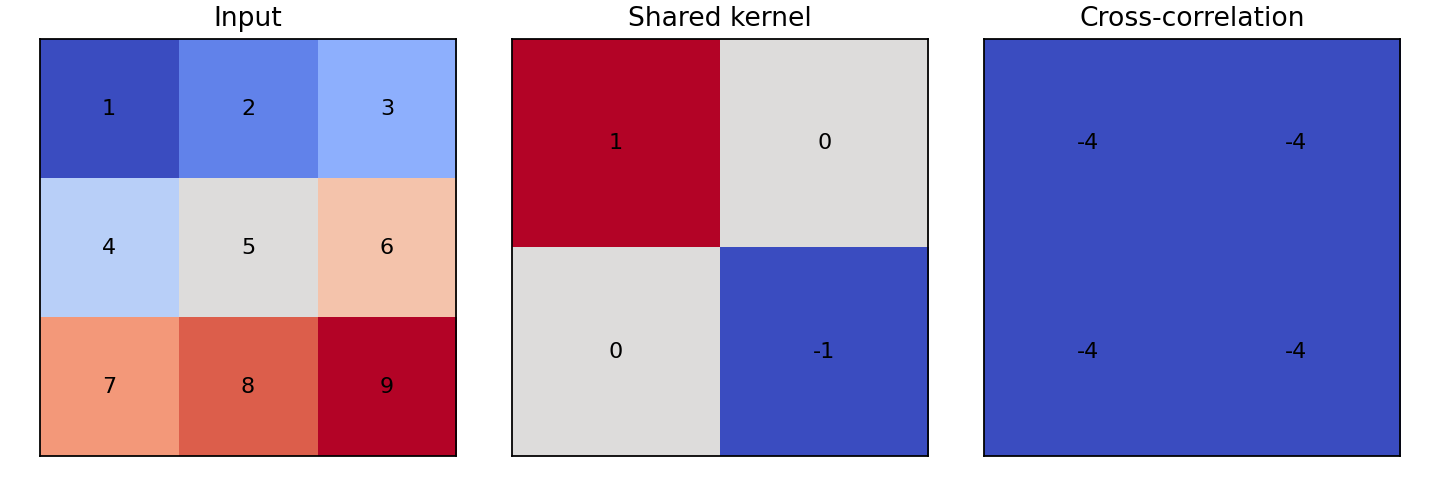

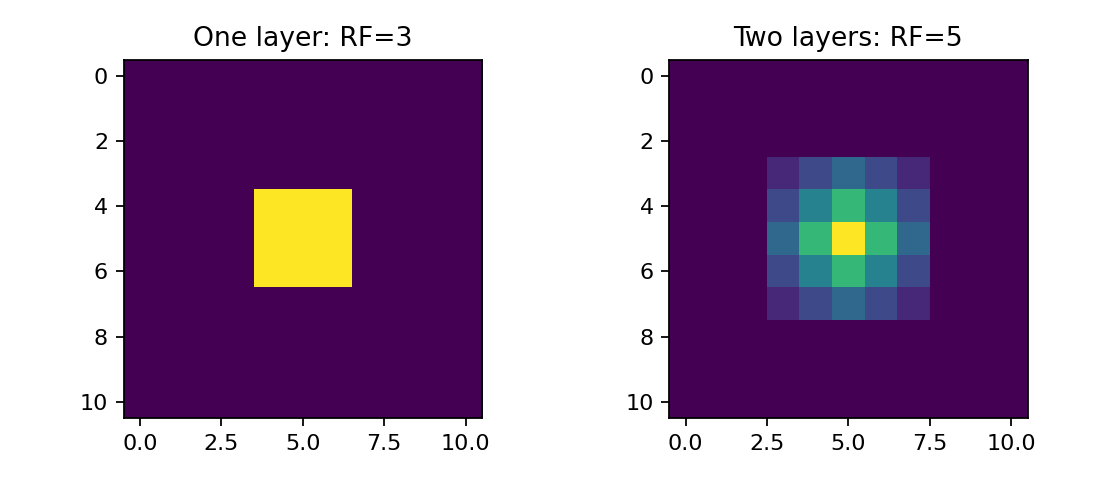

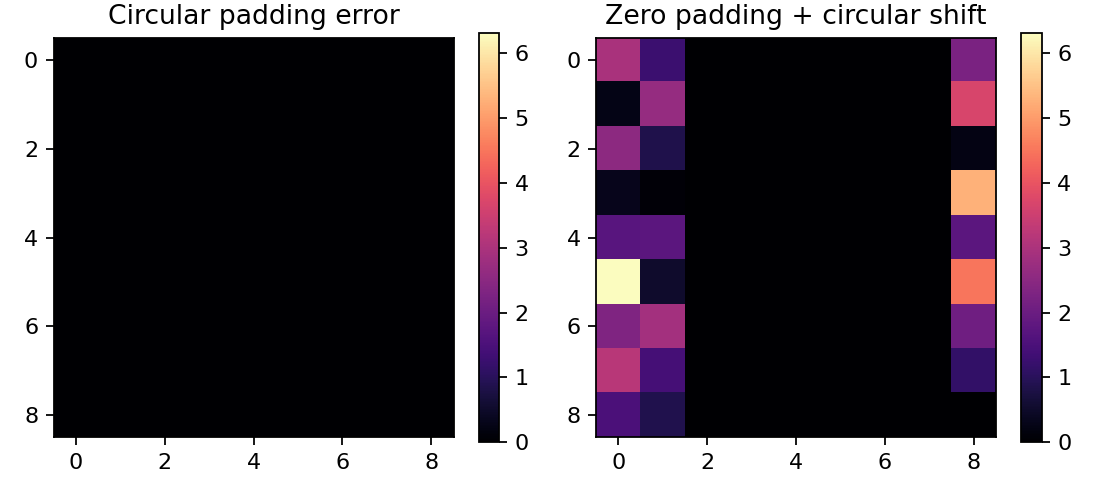

In [5]:
from IPython.display import display, Image
for p in sorted(pathlib.Path('figures').glob('*.png')):
    print(p.name)
    display(Image(filename=str(p)))

解释任务：逐项说明图中的控制变量、预算口径、失败对照和不能支持的结论。详细答案见answers.md。